<a href="https://colab.research.google.com/github/SENA-o7/pytorch-object-detector/blob/main/object_detector_proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

-----

# PyTorch ile Sıfırdan Nesne Tespit Modeli Eğitimi (Google Colab)




## 0. Veri Seti İncelemesi

### 0.1 Genel bakış
- **Kökeni:** Caltech-101 veri setinden özel olarak seçilmiş, **3 sınıflı hafif (lightweight) bir alt küme**.
- **Sınıflar (3 sınıf):**
  - `airplanes` → Uçaklar
  - `motorbikes` → Motosikletler
  - `schooners` → Yelkenli gemiler
- **Amaç:** Modele görüntüdeki nesnenin hem **ne olduğunu** (sınıflandırma) hem de **nerede olduğunu** (bounding box / regresyon) aynı anda öğretmek.

### 0.2 Veri yapısı ve etiketleme
Veri seti iki ana bileşenden oluşur:

**1) Görüntü dosyaları (`images/`)**
- Her sınıfa ait JPEG görseller bulunur.
- Görseller **farklı boyutlardadır** → modele vermeden önce sabit bir boyuta getirilmeleri (resize) gerekir.

**2) Annotation (etiket) dosyaları** (`airplanes.csv`, `motorbikes.csv`, `schooners.csv` ya da tek bir CSV)
- Her görüntü için nesneyi çevreleyen **bounding box (sınırlayıcı kutu)** koordinatlarını içerir.
- Tipik bir CSV satırı (ikinci satırdaki sayılar sadece örnektir):

```
filename, start_x, start_y, end_x, end_y, label
image_0001.jpg, 49, 30, 349, 137, airplanes
```

- `(start_x, start_y)` → kutunun **sol üst** köşesi
- `(end_x, end_y)` → kutunun **sağ alt** köşesi


### 0.3 Ön işleme ve model mimarisi ipuçları
**Kutu koordinatlarını yeniden ölçekleme (Bounding Box Rescaling)**
Görüntü sabit bir boyuta (örn. **224 × 224**) getirildiğinde kutu koordinatları da **aynı oranda** ölçeklenmelidir:

$$x_{yeni} = x_{eski} \cdot \frac{W_{yeni}}{W_{eski}} \qquad y_{yeni} = y_{eski} \cdot \frac{H_{yeni}}{H_{eski}}$$

Bu notebook'ta koordinatları görüntünün genişlik/yüksekliğine bölerek **0–1 arasına** çekiyoruz. Böylece görüntü hangi boyuta getirilirse getirilsin kutu doğru yerde kalır.

**İki başlı model çıktısı (Multi-task Learning)**
| Başlık (head) | Görevi | Çıktı | Kayıp fonksiyonu |
|---|---|---|---|
| Sınıflandırma başlığı | 3 sınıftan hangisi? | 3 olasılık (Softmax) | Categorical Cross-Entropy |
| Regresyon (bounding box) başlığı | Nesne nerede? | 4 sayı: `start_x, start_y, end_x, end_y` | MSE (Ortalama Kare Hata) |

Toplam kayıp = **sınıflandırma kaybı + kutu kaybı**. Model iki görevi aynı anda öğrenir.

## 1. Ortam Kontrolü


In [1]:
# Gerekli temel kütüphaneleri içe aktarıyoruz
import sys
import torch
import torchvision
import cv2
import numpy as np
import sklearn

# Ortamdaki sürümleri ekrana yazdırıyoruz (raporda "hangi sürümde çalıştı" sorusunun cevabı)
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("OpenCV      :", cv2.__version__)
print("NumPy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)

# GPU var mı kontrol ediyoruz
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("GPU bulunamadı!")

Python      : 3.13.15
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
OpenCV      : 4.14.0
NumPy       : 2.1.3
scikit-learn: 1.6.1
GPU         : Tesla T4


## 2. Veri setini Kaggle API ile indirme (Ödev Madde 2)

Kullanılan veri seti: **Caltech101 | Airplanes, Motorbikes & Schooners**
https://www.kaggle.com/datasets/maricinnamon/caltech101-airplanes-motorbikes-schooners

In [2]:
# Kaggle'ın yeni token yöntemi için güncel kaggle aracını kuruyoruz
!pip install -q --upgrade "kaggle>=1.8.0"

import os, getpass

token = getpass.getpass("Kaggle API token'ınızı yapıştırıp Enter'a basın: ").strip()

# Kaggle aracı token'ı bu ortam değişkeninden ve bu dosyadan okur
os.environ["KAGGLE_API_TOKEN"] = token
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
token_dosya = os.path.expanduser("~/.kaggle/access_token")
with open(token_dosya, "w") as f:
    f.write(token)
os.chmod(token_dosya, 0o600)   # Dosyayı izni sadece  bende
# Bağlantı testi: dosya listesi yazdırılırsa her şey yolunda
!kaggle datasets files maricinnamon/caltech101-airplanes-motorbikes-schooners | head -5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.9 MB/s eta 0:00:00
Kaggle API token'ınızı yapıştırıp Enter'a basın: ··········
Next Page Token = CfDJ8JDwKpgsc5hJpcljKjpYpOE5qVndr0Zsouut1w5RvAPPQLXOgAtzlk4R-90Y8pLLLSH_21NUu_EjyFwNG6cQlEM6l_o49weoNoND3-ZFYixd_ucle2GdL4PQ5JJQ6Rwj1xCmKLAvQ3wiTMSqXxd1I8ue7nBkhqkZjmLcEv5fRIl-EJunUqoMJTQV_Q
name                                                 size  creationDate                
---------------------------------------------------  ----  --------------------------  
caltech101_classification/Motorbikes/image_0001.jpg  6763  2022-09-14 10:10:54.654000  
caltech101_classification/Motorbikes/image_0002.jpg  6971  2022-09-14 10:10:54.717000  


In [3]:
!pip install -q --upgrade kaggle

# Veri setini /content/data klasörüne indirip zip'ten çıkarıyoruz
#  -d : "kullanıcı_adı/veri_seti_adı" formatında veri seti kimliği
#  -p : indirilecek klasör
#  --unzip : indirdikten sonra zip'i otomatik aç
!kaggle datasets download -d maricinnamon/caltech101-airplanes-motorbikes-schooners -p /content/data --unzip -q

print("İndirme tamamlandı.")

Dataset URL: https://www.kaggle.com/datasets/maricinnamon/caltech101-airplanes-motorbikes-schooners
License(s): CC-BY-NC-SA-4.0
İndirme tamamlandı.


In [19]:
import glob
import os
import shutil
import tarfile
import urllib.request
import zipfile

# Kaggle setinde bounding box yok; kutuları Caltech-101'in orijinal Annotations.tar arşivinden alıyoruz
CALTECH_URL = "https://data.caltech.edu/records/mzrjq-6wc02/files/caltech-101.zip?download=1"
ZIP_YOLU = "/content/caltech-101.zip"
GECICI = "/content/caltech_resmi"
GEREKLI_KLASORLER = ["Airplanes_Side_2", "Motorbikes_16", "schooner"]   # Bizim 3 sınıfın annotation klasörleri

def annotations_tar_bul():
    # Daha önce indirilmiş bir Annotations.tar varsa yolunu döndürür
    bulunan = glob.glob("/content/**/Annotations.tar", recursive=True)
    return bulunan[0] if bulunan else None

tar_yolu = annotations_tar_bul()

# ---- YOL 1: Caltech'in resmi sitesi ----
if tar_yolu is None:
    try:
        print("Caltech resmi sitesinden indiriliyor (~137 MB)...")
        # [DÜZELTME] Sunucu Python'un varsayılan isteğini 403 ile reddediyor;
        # tarayıcı gibi görünen bir User-Agent başlığı ekliyoruz
        istek = urllib.request.Request(CALTECH_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(istek) as cevap, open(ZIP_YOLU, "wb") as f:
            shutil.copyfileobj(cevap, f)
        # Zip'in içinden sadece Annotations.tar'ı çıkar
        with zipfile.ZipFile(ZIP_YOLU) as z:
            tar_adi = next(ad for ad in z.namelist() if ad.endswith("Annotations.tar"))
            z.extract(tar_adi, GECICI)
        tar_yolu = os.path.join(GECICI, tar_adi)
    except Exception as e:
        print("Resmi siteden indirilemedi:", e)
        # Yarım kalmış dosya varsa sil (bir sonraki denemede bozuk dosyayı okumasın)
        if os.path.exists(ZIP_YOLU):
            os.remove(ZIP_YOLU)

# ---- YOL 2 (yedek): torchvision'ın kendi Caltech-101 indiricisi ----
if tar_yolu is None:
    print("Yedek yol: torchvision ile indiriliyor...")
    !pip install -q gdown
    from torchvision.datasets import Caltech101
    try:
        Caltech101(root="/content/torchvision_caltech", target_type="annotation", download=True)
    except Exception as e:
        # İndirme bitip klasör açılırken hata olsa bile Annotations.tar inmiş olabilir
        print("torchvision uyarısı:", e)
    tar_yolu = annotations_tar_bul()

if tar_yolu is None:
    raise RuntimeError("Annotations.tar indirilemedi. Hata mesajını kontrol edin.")
print("Annotations.tar bulundu:", tar_yolu)

# ---- Sadece bizim 3 sınıfın .mat dosyalarını /content/data/Annotations altına çıkar ----
with tarfile.open(tar_yolu) as t:
    uyeler = [m for m in t.getmembers()
              if any(f"Annotations/{k}/" in m.name for k in GEREKLI_KLASORLER)]
    try:
        t.extractall("/content/data", members=uyeler, filter="data")  # Python 3.12+: güvenli çıkarma
    except TypeError:
        t.extractall("/content/data", members=uyeler)                  # Eski

Caltech resmi sitesinden indiriliyor (~137 MB)...
Annotations.tar bulundu: /content/caltech_resmi/caltech-101/Annotations.tar


In [20]:
 # İndirilen klasörün yapısına bakıyoruz (ilk 3 seviye).
# Böylece görsellerin ve annotation (bounding box) dosyalarının nerede olduğunu görebiliriz.
import os

VERI_KOK = "/content/data"

for kok, klasorler, dosyalar in os.walk(VERI_KOK):
    seviye = kok.replace(VERI_KOK, "").count(os.sep)
    if seviye > 3:
        continue  # Çok derin klasörleri yazdırmıyoruz
    girinti = "    " * seviye
    print(f"{girinti}{os.path.basename(kok) or kok}/  ({len(dosyalar)} dosya)")
    # Her klasördeki ilk 3 dosyayı örnek olarak göster
    for d in sorted(dosyalar)[:3]:
        print(f"{girinti}    - {d}")

data/  (0 dosya)
    Annotations/  (0 dosya)
        Motorbikes_16/  (798 dosya)
            - annotation_0001.mat
            - annotation_0002.mat
            - annotation_0003.mat
        schooner/  (63 dosya)
            - annotation_0001.mat
            - annotation_0002.mat
            - annotation_0003.mat
        Airplanes_Side_2/  (800 dosya)
            - annotation_0001.mat
            - annotation_0002.mat
            - annotation_0003.mat
    caltech101_classification/  (0 dosya)
        Motorbikes/  (798 dosya)
            - image_0001.jpg
            - image_0002.jpg
            - image_0003.jpg
        schooner/  (63 dosya)
            - image_0001.jpg
            - image_0002.jpg
            - image_0003.jpg
        airplanes/  (800 dosya)
            - image_0001.jpg
            - image_0002.jpg
            - image_0003.jpg


## 3. Proje dosyalarını oluşturma (`pyimagesearch/` paketi)

Aşağıdaki her hücre, başındaki `%%writefile` komutu sayesinde **çalıştırılmaz, diske dosya olarak kaydedilir.** Hücreyi çalıştırınca çıktıda `Writing pyimagesearch/config.py` gibi bir satır görürsünüz.


In [6]:
# pyimagesearch klasörünü (Python paketi) ve çıktı klasörlerini oluşturuyoruz
import os
os.makedirs("/content/pyimagesearch", exist_ok=True)
os.makedirs("/content/output/plots", exist_ok=True)

# Colab'ın çalışma klasörünü /content yapıyoruz (dosyalar burada oluşacak)
%cd /content

/content


In [7]:
%%writefile pyimagesearch/__init__.py
# Bu dosya boş olabilir. Varlığı, Python'a "pyimagesearch klasörü bir paket" der.
# Böylece başka dosyalardan "from pyimagesearch import config" şeklinde içe aktarabiliriz.

Writing pyimagesearch/__init__.py


In [8]:
%%writefile pyimagesearch/config.py
# ============================================================================
# config.py : Projenin TÜM ayarları tek yerde.
# Eğitim (train.py) ve çıkarım (predict.py) bu dosyadaki değerleri kullanır.
# ============================================================================
import os
import torch

# ---------------- Klasör yolları ----------------
# Kaggle'dan indirilen verinin kök klasörü
BASE_PATH = "/content/data"

# Eğitim çıktılarının kaydedileceği klasör
BASE_OUTPUT = "/content/output"

# Kaydedilecek dosyalar (orijinal projedeki isimlerle aynı)
MODEL_PATH        = os.path.join(BASE_OUTPUT, "detector.pth")          # Eğitilmiş modelin tamamı
MODEL_WEIGHTS     = os.path.join(BASE_OUTPUT, "detector_weights.pth")  # Sadece ağırlıklar (daha güvenli format)
LE_PATH           = os.path.join(BASE_OUTPUT, "le.pickle")             # Etiket kodlayıcı (LabelEncoder)
PLOTS_PATH        = os.path.join(BASE_OUTPUT, "plots")                 # Grafik klasörü
PLOT_PATH         = os.path.join(PLOTS_PATH, "training.png")           # Loss/Accuracy grafiği
HISTORY_PATH      = os.path.join(BASE_OUTPUT, "history.json")          # [EK] Epoch sonuçları (notebook'ta grafik için)
TEST_PATHS        = os.path.join(BASE_OUTPUT, "test_paths.txt")        # Test görsellerinin listesi

# ---------------- Cihaz ----------------
# GPU varsa "cuda", yoksa "cpu" kullanılacak
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# GPU kullanıyorsak DataLoader'da pin_memory açmak veri aktarımını hızlandırır
PIN_MEMORY = True if DEVICE == "cuda" else False

# ---------------- Görüntü ön işleme ----------------
# ResNet50 224x224 boyutunda görüntülerle eğitilmiştir
INPUT_SIZE = 224
# ImageNet ortalama ve standart sapma değerleri (pretrained model bu değerlerle eğitildi)
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# ---------------- Eğitim hiperparametreleri ----------------
INIT_LR    = 1e-4   # Öğrenme oranı (learning rate)
NUM_EPOCHS = 20     # Kaç tur eğitim yapılacağı
BATCH_SIZE = 32     # Her adımda modele verilecek görüntü sayısı
TEST_SPLIT = 0.20   # Verinin %20'si test için ayrılacak

# Toplam kayıp = LABELS * sınıflandırma kaybı + BBOX * kutu kaybı
# Bu ağırlıklarla iki görevden hangisine daha çok önem verileceğini ayarlayabiliriz
LABELS = 1.0
BBOX   = 1.0

# [SÜRÜM DÜZELTMESİ] Orijinal kod DataLoader'da num_workers=os.cpu_count() kullanıyordu.
# Colab'da bu, "This DataLoader will create N worker processes..." uyarısına ve
# bazen takılmalara yol açıyor. Colab için 2 worker güvenli bir değer.
NUM_WORKERS = 2

Writing pyimagesearch/config.py


In [9]:
%%writefile pyimagesearch/custom_tensor_dataset.py
# ============================================================================
# custom_tensor_dataset.py : PyTorch'un DataLoader'ına veriyi örnek örnek veren sınıf.
# DataLoader her adımda bu sınıftan (görüntü, etiket, kutu) üçlüsü ister.
# ============================================================================
from torch.utils.data import Dataset


class CustomTensorDataset(Dataset):

    def __init__(self, tensors, transforms=None):
        # tensors = (görüntüler, etiketler, kutular) üçlüsü
        self.tensors = tensors
        # Görüntüye uygulanacak dönüşümler (tensöre çevirme, normalize etme)
        self.transforms = transforms

    def __getitem__(self, index):
        # index numaralı örneği alıyoruz
        image = self.tensors[0][index]
        label = self.tensors[1][index]
        bbox  = self.tensors[2][index]

        # [UYARLAMA] Orijinal kod görüntüyü önce tensöre çevirip image.permute(2, 0, 1) ile
        # kanal sırasını (H,W,C) -> (C,H,W) yapıyordu. Biz görüntüyü uint8 NumPy (H,W,C)
        # olarak tutuyoruz (4 kat az RAM); ToPILImage + ToTensor bu çevirmeyi kendisi yapıyor.
        if self.transforms:
            image = self.transforms(image)

        return (image, label, bbox)

    def __len__(self):
        # Veri setindeki toplam örnek sayısı
        return self.tensors[0].shape[0]

Writing pyimagesearch/custom_tensor_dataset.py


In [10]:
%%writefile pyimagesearch/bbox_regressor.py
# ============================================================================
# bbox_regressor.py : Nesne tespit modelinin mimarisi.
# Gövde (baseModel, ResNet50): görüntüden 2048 boyutlu özellik vektörü çıkarır.
# Bu vektörün üstüne iki ayrı "kafa" eklenir:
#   1) regressor  -> kutunun 4 koordinatı (xmin, ymin, xmax, ymax)
#   2) classifier -> sınıf skorları (uçak / motosiklet / yelkenli)
# ============================================================================
from torch.nn import Dropout, Identity, Linear, Module, ReLU, Sequential, Sigmoid


class ObjectDetector(Module):

    def __init__(self, baseModel, numClasses):
        super(ObjectDetector, self).__init__()
        self.baseModel = baseModel
        self.numClasses = numClasses

        # ResNet50'nin son katmanının giriş boyutu
        in_features = baseModel.fc.in_features

        # --- Bounding box regresör kafası ---
        # 4 çıkış. Sigmoid ile 0-1 aralığına sıkıştırılır,
        # çünkü eğitimde kutu koordinatlarını görüntü boyutuna bölerek 0-1 aralığına getirdik.
        self.regressor = Sequential(
            Linear(in_features, 128),
            ReLU(),
            Linear(128, 64),
            ReLU(),
            Linear(64, 32),
            ReLU(),
            Linear(32, 4),
            Sigmoid(),
        )

        # --- Sınıflandırıcı---
        # Dropout: eğitimde nöronların bir kısmını rastgele kapatarak ezberlemeyi  azaltır
        self.classifier = Sequential(
            Linear(in_features, 512),
            ReLU(),
            Dropout(),
            Linear(512, 512),
            ReLU(),
            Dropout(),
            Linear(512, self.numClasses),
        )

        # ResNet50'nin kendi 1000 sınıflık son katmanını (fc) devre dışı bırakıyoruz.
        # Identity girdiyi hiç değiştirmeden geçirir; böylece gövdeden ham özellik vektörünü alırız.
        self.baseModel.fc = Identity()

    def forward(self, x):
        # Görüntüden özellik çıkar, sonra aynı özellikleri iki kafaya ayrı ayrı ver
        features = self.baseModel(x)
        bboxes = self.regressor(features)
        classLogits = self.classifier(features)
        return (bboxes, classLogits)

Writing pyimagesearch/bbox_regressor.py


In [11]:
%%writefile pyimagesearch/veri_okuyucu.py
# ============================================================================
# veri_okuyucu.py : [EK DOSYA] Orijinal projede yok.
# Orijinal eğitimde annotation'lar tek bir CSV'deydi. Kaggle'daki veri setinin formatı
# farklı olabileceği için bu dosya iki formatı da otomatik tanır:
#   - CSV/TXT dosyaları : satırdaki dosya adı + son 4 sayı = kutu koordinatı
#   - Caltech'in orijinal .mat dosyaları : box_coord alanı (sıra: ymin, ymax, xmin, xmax)
# Koordinat sırası belirsizse görüntü boyutuna sığan geçerli sıra seçilir.
# ============================================================================
import glob
import os
import re

import cv2
import pandas as pd
from scipy.io import loadmat

# Görüntü dosyası uzantıları
GORUNTU_UZANTILARI = (".jpg", ".jpeg", ".png", ".bmp")

# Caltech-101'de annotation klasör adları görsel klasör adlarından farklıdır.
CALTECH_ANNOT_ESLESME = {
    "airplanes_side_2": "airplanes",
    "motorbikes_16": "motorbikes",
    "faces_2": "faces",
    "faces_3": "faces_easy",
}


def sinif_adi_normalize(ad):
    # Sınıf adlarını küçük harfe çevirip karşılaştırmayı kolaylaştırıyoruz
    ad = ad.lower().strip()
    return CALTECH_ANNOT_ESLESME.get(ad, ad)


def sayi_mi(deger):
    # Bir hücrenin sayıya çevrilip çevrilemediğini kontrol eder
    try:
        float(str(deger).strip())
        return True
    except ValueError:
        return False


def goruntu_numarasi(dosya_adi):
    # "image_0001.jpg" veya "annotation_0001.mat" gibi isimlerden 1 sayısını çıkarır
    sayilar = re.findall(r"\d+", os.path.splitext(os.path.basename(dosya_adi))[0])
    return int(sayilar[-1]) if sayilar else None


def kutuyu_dogrula(dortlu, w, h, once_matlab=False):
    # 4 sayının (xmin, ymin, xmax, ymax) mı yoksa Matlab sırası (ymin, ymax, xmin, xmax) mı
    # olduğuna karar verir. Görüntü sınırlarına sığan ve geçerli olan sırayı döndürür.
    a, b, c, d = [float(v) for v in dortlu]
    python_sirasi = (a, b, c, d)
    matlab_sirasi = (c, a, d, b)
    sira = [matlab_sirasi, python_sirasi] if once_matlab else [python_sirasi, matlab_sirasi]
    for x1, y1, x2, y2 in sira:
        # Kutu geçerli mi? (sol < sağ, üst < alt, görüntü içinde; 2 piksel tolerans)
        if x1 < x2 and y1 < y2 and x1 >= -2 and y1 >= -2 and x2 <= w + 2 and y2 <= h + 2:
            # Görüntü dışına taşan birkaç pikseli kırpıyoruz
            return (max(0, x1), max(0, y1), min(w, x2), min(h, y2))
    return None  # Hiçbir sıra geçerli değilse bu örnek atlanır


def annotationlari_oku(kok, ayrintili=True):
    # Ana fonksiyon. Dönüş: {goruntu_yolu: (sinif, xmin, ymin, xmax, ymax)} sözlüğü

    # ---- 1) Tüm görselleri bul; sınıf = bulunduğu klasörün adı ----
    goruntuler = []
    for yol in glob.glob(os.path.join(kok, "**", "*"), recursive=True):
        if yol.lower().endswith(GORUNTU_UZANTILARI):
            goruntuler.append((yol, os.path.basename(os.path.dirname(yol))))

    # Hızlı arama için iki indeks:
    #   ada_gore           (aynı ad farklı sınıflarda olabilir)
    #   sinif_numara_gore  (.mat dosyalarını eşlemek için)
    ada_gore, sinif_numara_gore = {}, {}
    for yol, sinif in goruntuler:
        ada_gore.setdefault(os.path.basename(yol).lower(), []).append((yol, sinif))
        sinif_numara_gore[(sinif_adi_normalize(sinif), goruntu_numarasi(yol))] = (yol, sinif)

    def dosya_adindan_goruntu(ad, ipucu=""):
        # CSV'deki dosya adından gerçek görüntüyü bulur. Her sınıfta image_0001.jpg olduğu için
        # birden fazla aday varsa, CSV yolunda geçen sınıf adını ipucu olarak kullanır.
        adaylar = ada_gore.get(os.path.basename(str(ad)).lower().strip(), [])
        if len(adaylar) == 1:
            return adaylar[0]
        ipucu = ipucu.lower()
        for yol, sinif in adaylar:
            if sinif.lower() in ipucu or sinif_adi_normalize(sinif) in ipucu:
                return (yol, sinif)
        for yol, sinif in adaylar:
            if str(ad).replace("\\", "/").lower() in yol.replace("\\", "/").lower():
                return (yol, sinif)
        return None

    # Her görüntünün boyutunu bir kez okuyup saklıyoruz
    boyutlar = {}
    def boyut(yol):
        if yol not in boyutlar:
            img = cv2.imread(yol)
            boyutlar[yol] = None if img is None else (img.shape[1], img.shape[0])  # (w, h)
        return boyutlar[yol]

    kayitlar, atlanan = {}, 0

    # ---- 2) CSV / TXT annotation dosyaları ----
    for csv_yolu in glob.glob(os.path.join(kok, "**", "*.csv"), recursive=True) + \
                    glob.glob(os.path.join(kok, "**", "*.txt"), recursive=True):
        try:
            # sep=None: virgül/noktalı virgül/boşluk ayracını otomatik tanır
            # header=None: başlık satırı sayı içermediği için aşağıda kendiliğinden atlanır
            df = pd.read_csv(csv_yolu, header=None, sep=None, engine="python", dtype=str)
        except Exception as e:
            print("CSV okunamadı:", csv_yolu, "->", e)
            continue
        csv_govde = os.path.splitext(os.path.basename(csv_yolu))[0].lower()
        for _, satir in df.iterrows():
            hucreler = [str(v).strip() for v in satir.tolist() if str(v).strip() not in ("", "nan")]
            dosya_hucresi = next((v for v in hucreler if v.lower().endswith(GORUNTU_UZANTILARI)), None)
            sayilar = [float(v) for v in hucreler if sayi_mi(v)]
            if len(sayilar) < 4:
                continue  # Başlık satırı ya da kutu içermeyen satır
            if dosya_hucresi is not None:
                eslesme = dosya_adindan_goruntu(dosya_hucresi, ipucu=csv_yolu + " " + " ".join(hucreler))
            else:
                # Satırda dosya adı yoksa: görsel başına bir CSV (image_0001.csv -> image_0001.jpg)
                eslesme = dosya_adindan_goruntu(csv_govde + ".jpg", ipucu=csv_yolu)
            if eslesme is None or boyut(eslesme[0]) is None:
                atlanan += 1
                continue
            yol, sinif = eslesme
            # Son 4 sayı = kutu. (PyImageSearch: ad,x1,y1,x2,y2 ; VOC: ad,w,h,sınıf,x1,y1,x2,y2)
            kutu = kutuyu_dogrula(sayilar[-4:], *boyut(yol))
            if kutu is None:
                atlanan += 1
                continue
            kayitlar[yol] = (sinif, *kutu)

    # ---- 3) Caltech'in orijinal .mat annotation dosyaları ----
    for mat_yolu in glob.glob(os.path.join(kok, "**", "*.mat"), recursive=True):
        try:
            mat = loadmat(mat_yolu)
        except Exception:
            atlanan += 1
            continue
        if "box_coord" not in mat:
            continue
        # .mat'ın bulunduğu klasörün adı sınıf adıdır (Airplanes_Side_2 -> airplanes)
        sinif_ipucu = sinif_adi_normalize(os.path.basename(os.path.dirname(mat_yolu)))
        eslesme = sinif_numara_gore.get((sinif_ipucu, goruntu_numarasi(mat_yolu)))
        if eslesme is None or boyut(eslesme[0]) is None:
            atlanan += 1
            continue
        yol, sinif = eslesme
        # Caltech box_coord sırası: [ymin, ymax, xmin, xmax]
        kutu = kutuyu_dogrula(mat["box_coord"][0], *boyut(yol), once_matlab=True)
        if kutu is None:
            atlanan += 1
            continue
        kayitlar[yol] = (sinif, *kutu)

    if ayrintili:
        print(f"Bulunan görüntü: {len(goruntuler)} | Bounding box'ı bulunan: {len(kayitlar)} | Atlanan satır: {atlanan}")
        print(pd.Series([v[0] for v in kayitlar.values()], dtype=str).value_counts().to_string())

    if len(kayitlar) == 0:
        raise RuntimeError(
            "Hiç annotation bulunamadı! Klasör ağacına bakın ve annotation dosyalarının formatını "
            "kontrol edin; gerekirse bu dosyadaki CSV okuma kısmını kendi formatınıza göre düzenleyin."
        )
    return kayitlar

Writing pyimagesearch/veri_okuyucu.py


### Annotation'ları kontrol etme
Eğitime başlamadan önce kutuların doğru okunduğunu gözle kontrol ediyoruz: her sınıftan bir görüntü, üzerinde gerçek kutusuyla çizilir. Kutu nesnenin üstünde değilse koordinat sırası yanlış okunmuştur.

Bulunan görüntü: 1661 | Bounding box'ı bulunan: 1661 | Atlanan satır: 0
airplanes     800
Motorbikes    798
schooner       63


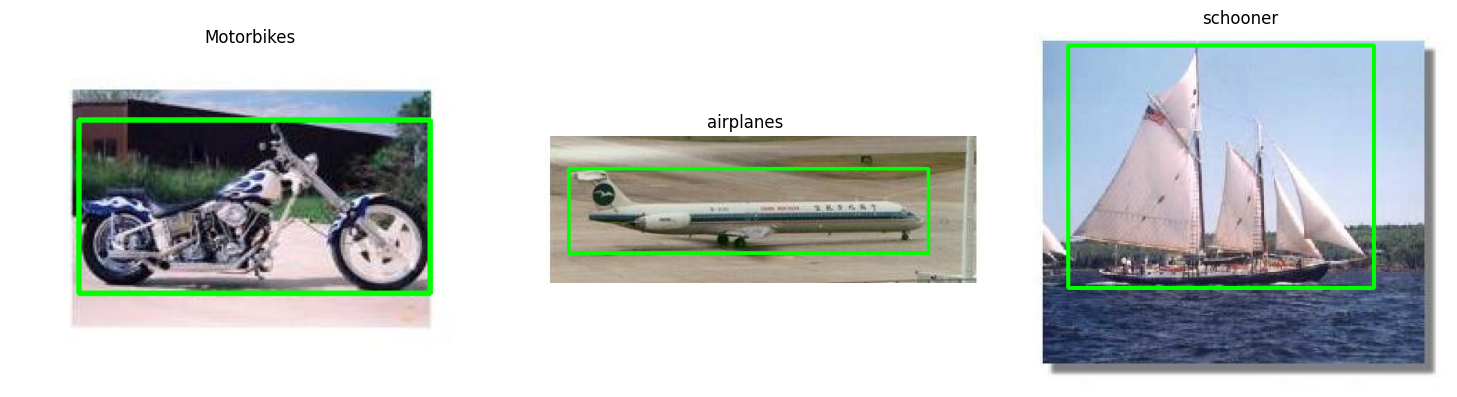

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pyimagesearch import config
from pyimagesearch.veri_okuyucu import annotationlari_oku

# Annotation'ları okuyup sınıf başına sayıları yazdırıyoruz
kayitlar = annotationlari_oku(config.BASE_PATH)

# Her sınıftan ilk görüntüyü kutusuyla çiziyoruz
siniflar = sorted(set(v[0] for v in kayitlar.values()))
fig, eksenler = plt.subplots(1, len(siniflar), figsize=(5 * len(siniflar), 4))
eksenler = np.atleast_1d(eksenler)
for eksen, sinif in zip(eksenler, siniflar):
    yol = next(k for k, v in kayitlar.items() if v[0] == sinif)
    _, x1, y1, x2, y2 = kayitlar[yol]
    img = cv2.cvtColor(cv2.imread(yol), cv2.COLOR_BGR2RGB)                         # OpenCV BGR okur
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)     # Yeşil kutu
    eksen.imshow(img)
    eksen.set_title(sinif)
    eksen.axis("off")
plt.tight_layout()
plt.show()

## 4. Eğitim : `train.py` (Ödev Madde 1)

Orijinal `train.py`'nin adımları:
1. Annotation'ları oku, görüntüleri 224×224'e küçült, kutuları 0–1 aralığına normalize et.
2. Sınıf isimlerini `LabelEncoder` ile sayıya çevir, veriyi %80 / %20 ayır.
3. Modeli kur (dondurulmuş ResNet50 + iki kafa), 20 epoch eğit.
4. Modeli, etiket kodlayıcıyı, test listesini, epoch geçmişini ve grafiği kaydet.

In [22]:
%%writefile train.py
# ============================================================================
# train.py : Nesne tespit modelini eğitir ve tüm çıktıları output/ klasörüne kaydeder.
# *******Çalıştırma: !python train.py*****
# ============================================================================
import json
import os
import pickle
import time

import cv2
import matplotlib
matplotlib.use("Agg")  # Betik terminalden çalıştığı için grafiği ekrana değil dosyaya çiziyoruz
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.nn import CrossEntropyLoss, MSELoss
from torch.optim import Adam
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50

from pyimagesearch import config
from pyimagesearch.bbox_regressor import ObjectDetector
from pyimagesearch.custom_tensor_dataset import CustomTensorDataset
from pyimagesearch.veri_okuyucu import annotationlari_oku


def main():
    os.makedirs(config.PLOTS_PATH, exist_ok=True)

    # ------------------------------------------------------------------
    # 1) Veriyi yükle
    # ------------------------------------------------------------------
    print("[BİLGİ] Veri seti yükleniyor...")
    kayitlar = annotationlari_oku(config.BASE_PATH)

    data, labels, bboxes, imagePaths = [], [], [], []
    for yol, (sinif, x1, y1, x2, y2) in kayitlar.items():
        image = cv2.imread(yol)
        (h, w) = image.shape[:2]

        # Kutu koordinatlarını görüntü boyutuna bölerek 0-1 aralığına getiriyoruz.
        # Böylece görüntü boyutundan bağımsız olurlar (modelin Sigmoid çıkışıyla da uyumlu).
        bboxes.append((x1 / w, y1 / h, x2 / w, y2 / h))

        # OpenCV görüntüyü BGR okur; ResNet RGB ile eğitildiği için çeviriyoruz
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        # Model girişi için 224x224 boyutuna getiriyoruz
        image = cv2.resize(image, (config.INPUT_SIZE, config.INPUT_SIZE))

        data.append(image)
        labels.append(sinif)
        imagePaths.append(yol)

    # Görüntüleri uint8 olarak tutuyoruz (float32'ye göre 4 kat az RAM)
    data = np.array(data, dtype="uint8")
    bboxes = np.array(bboxes, dtype="float32")
    labels = np.array(labels)
    imagePaths = np.array(imagePaths)

    # Sınıf isimlerini sayıya çeviriyoruz (örn. "Motorbikes" -> 0, "airplanes" -> 1 ...)
    le = LabelEncoder()
    labels = le.fit_transform(labels)
    print("[BİLGİ] Sınıflar:", [str(c) for c in le.classes_])

    # ------------------------------------------------------------------
    # 2) Train / test ayırma
    # stratify: her sınıfın oranı iki kümede de aynı kalsın (sınıflar dengesiz olduğu için önemli)
    # ------------------------------------------------------------------
    (trainImages, testImages, trainLabels, testLabels,
     trainBBoxes, testBBoxes, trainPaths, testPaths) = train_test_split(
        data, labels, bboxes, imagePaths,
        test_size=config.TEST_SPLIT, random_state=42, stratify=labels)
    print(f"[BİLGİ] Eğitim: {len(trainImages)} örnek | Test: {len(testImages)} örnek")

    # Test görsellerinin yollarını kaydediyoruz (inference'ta eğitimde görülmemiş görselleri kullanmak için)
    with open(config.TEST_PATHS, "w") as f:
        f.write("\n".join(testPaths))

    # ------------------------------------------------------------------
    # 3) Dataset ve DataLoader
    # ------------------------------------------------------------------
    # ToPILImage -> ToTensor (0-255 -> 0-1, (H,W,C) -> (C,H,W)) -> ImageNet normalize
    transforms_ = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=config.MEAN, std=config.STD),
    ])

    trainDS = CustomTensorDataset((trainImages, torch.tensor(trainLabels), torch.tensor(trainBBoxes)),
                                  transforms=transforms_)
    testDS = CustomTensorDataset((testImages, torch.tensor(testLabels), torch.tensor(testBBoxes)),
                                 transforms=transforms_)

    # Eğitimde shuffle=True: her epoch'ta örneklerin sırası karışır (model sıraya alışmasın)
    trainLoader = DataLoader(trainDS, batch_size=config.BATCH_SIZE, shuffle=True,
                             num_workers=config.NUM_WORKERS, pin_memory=config.PIN_MEMORY)
    testLoader = DataLoader(testDS, batch_size=config.BATCH_SIZE, shuffle=False,
                            num_workers=config.NUM_WORKERS, pin_memory=config.PIN_MEMORY)

    # ------------------------------------------------------------------
    # 4) Model
    # ------------------------------------------------------------------
    # [SÜRÜM DÜZELTMESİ] Orijinal kod: resnet50(pretrained=True)
    # torchvision 0.13'ten itibaren "pretrained" kullanımdan kaldırıldı (önce uyarı, güncel
    # sürümlerde hata). Yeni kullanım: weights=ResNet50_Weights.DEFAULT
    resnet = resnet50(weights=ResNet50_Weights.DEFAULT)

    # Gövdeyi donduruyoruz: ImageNet'te öğrendiği ağırlıklar değişmesin, sadece yeni kafalar eğitilsin.
    # Az veriyle daha kararlı ve çok daha hızlı eğitim sağlar (transfer learning).
    for param in resnet.parameters():
        param.requires_grad = False

    objectDetector = ObjectDetector(resnet, len(le.classes_)).to(config.DEVICE)

    # Kayıp fonksiyonları
    classLossFunc = CrossEntropyLoss()   # Sınıflandırma hatası
    bboxLossFunc = MSELoss()             # Kutu koordinatlarındaki hata (regresyon)

    # Sadece eğitilebilir (requires_grad=True) parametreleri, yani kafaları optimize ediyoruz
    opt = Adam(filter(lambda p: p.requires_grad, objectDetector.parameters()), lr=config.INIT_LR)

    # Epoch geçmişi (grafikler için)
    H = {"total_train_loss": [], "total_val_loss": [],
         "train_bbox_loss": [], "val_bbox_loss": [],
         "train_class_acc": [], "val_class_acc": []}

    def bir_epoch(loader, egitim):
        # Veri üzerinden bir tur geçer; egitim=True ise ağırlıkları günceller.
        # Dönüş: (ortalama toplam kayıp, ortalama kutu kaybı, accuracy)
        objectDetector.train() if egitim else objectDetector.eval()  # Dropout aç/kapat
        toplamKayip, toplamKutu, dogru, ornek = 0.0, 0.0, 0, 0

        # Değerlendirmede gradyan hesaplamıyoruz (hız ve bellek tasarrufu)
        with torch.set_grad_enabled(egitim):
            for (images, lbls, boxes) in loader:
                images = images.to(config.DEVICE, non_blocking=True)
                lbls = lbls.to(config.DEVICE, non_blocking=True)
                boxes = boxes.to(config.DEVICE, non_blocking=True)

                # İleri yayılım: model (kutular, sınıf skorları) döndürür
                predBBoxes, predLogits = objectDetector(images)

                # İki kaybı ağırlıklı topluyoruz
                bboxLoss = bboxLossFunc(predBBoxes, boxes)
                classLoss = classLossFunc(predLogits, lbls)
                totalLoss = (config.BBOX * bboxLoss) + (config.LABELS * classLoss)

                if egitim:
                    opt.zero_grad()       # Önceki adımın gradyanlarını sıfırla
                    totalLoss.backward()  # Gradyanları hesapla (geri yayılım)
                    opt.step()            # Ağırlıkları güncelle

                n = images.size(0)
                toplamKayip += totalLoss.item() * n
                toplamKutu += bboxLoss.item() * n
                dogru += (predLogits.argmax(1) == lbls).sum().item()
                ornek += n
        return toplamKayip / ornek, toplamKutu / ornek, dogru / ornek

    # ------------------------------------------------------------------
    # 5) Eğitim döngüsü
    # ------------------------------------------------------------------
    print("[BİLGİ] Eğitim başlıyor...")
    baslangic = time.time()
    for epoch in range(config.NUM_EPOCHS):
        trLoss, trBox, trAcc = bir_epoch(trainLoader, egitim=True)
        vaLoss, vaBox, vaAcc = bir_epoch(testLoader, egitim=False)

        H["total_train_loss"].append(trLoss); H["total_val_loss"].append(vaLoss)
        H["train_bbox_loss"].append(trBox);   H["val_bbox_loss"].append(vaBox)
        H["train_class_acc"].append(trAcc);   H["val_class_acc"].append(vaAcc)

        print(f"Epoch {epoch + 1:2d}/{config.NUM_EPOCHS} | "
              f"Train loss: {trLoss:.4f}  acc: {trAcc:.4f} | "
              f"Val loss: {vaLoss:.4f}  acc: {vaAcc:.4f}")
    print(f"[BİLGİ] Toplam eğitim süresi: {time.time() - baslangic:.1f} sn")

    # ------------------------------------------------------------------
    # 6) Kaydetme
    # ------------------------------------------------------------------
    # Orijinal projedeki gibi modelin TAMAMINI kaydediyoruz
    torch.save(objectDetector, config.MODEL_PATH)
    # Ayrıca sadece ağırlıkları (state_dict) kaydediyoruz: PyTorch'un önerdiği güvenli format
    torch.save(objectDetector.state_dict(), config.MODEL_WEIGHTS)
    # LabelEncoder: tahminde sayıyı tekrar sınıf ismine çevirmek için
    with open(config.LE_PATH, "wb") as f:
        pickle.dump(le, f)
    # Epoch geçmişi: notebook'ta grafikleri tekrar çizebilmek için
    with open(config.HISTORY_PATH, "w") as f:
        json.dump(H, f)

    # ------------------------------------------------------------------
    # 7) Loss ve Accuracy grafiği (dosyaya)
    # ------------------------------------------------------------------
    epochlar = range(1, config.NUM_EPOCHS + 1)
    plt.style.use("ggplot")
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
    ax1.plot(epochlar, H["total_train_loss"], marker="o", label="Eğitim (train) loss")
    ax1.plot(epochlar, H["total_val_loss"], marker="o", label="Doğrulama (val) loss")
    ax1.set_title("Toplam Loss (sınıf + kutu)"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()
    ax2.plot(epochlar, H["train_class_acc"], marker="o", label="Eğitim (train) accuracy")
    ax2.plot(epochlar, H["val_class_acc"], marker="o", label="Doğrulama (val) accuracy")
    ax2.set_title("Sınıflandırma Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
    ax2.set_ylim(0, 1.05); ax2.legend()
    ax3.plot(epochlar, H["train_bbox_loss"], marker="o", label="Eğitim (train) bbox loss")
    ax3.plot(epochlar, H["val_bbox_loss"], marker="o", label="Doğrulama (val) bbox loss")
    ax3.set_title("Bounding Box Loss (MSE)"); ax3.set_xlabel("Epoch"); ax3.set_ylabel("MSE"); ax3.legend()
    plt.tight_layout()
    plt.savefig(config.PLOT_PATH, dpi=120)

    print("[BİLGİ] Kaydedilenler:", config.MODEL_PATH, config.MODEL_WEIGHTS, config.LE_PATH, config.PLOT_PATH)


# Dosya doğrudan çalıştırıldığında (python train.py) main() çağrılır;
# başka bir dosyadan import edildiğinde eğitim kendiliğinden başlamaz.
if __name__ == "__main__":
    main()

Writing train.py


In [23]:
# Eğitimi başlatıyoruz (T4 GPU'da yaklaşık 5-15 dakika sürer)
!python train.py

[BİLGİ] Veri seti yükleniyor...
Bulunan görüntü: 1661 | Bounding box'ı bulunan: 1661 | Atlanan satır: 0
airplanes     800
Motorbikes    798
schooner       63
[BİLGİ] Sınıflar: ['Motorbikes', 'airplanes', 'schooner']
[BİLGİ] Eğitim: 1328 örnek | Test: 333 örnek
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 209MB/s]
[BİLGİ] Eğitim başlıyor...
Epoch  1/20 | Train loss: 0.8744  acc: 0.8607 | Val loss: 0.4612  acc: 0.9550
Epoch  2/20 | Train loss: 0.2716  acc: 0.9571 | Val loss: 0.1431  acc: 0.9610
Epoch  3/20 | Train loss: 0.1099  acc: 0.9578 | Val loss: 0.0805  acc: 0.9730
Epoch  4/20 | Train loss: 0.0757  acc: 0.9759 | Val loss: 0.0487  acc: 0.9910
Epoch  5/20 | Train loss: 0.0414  acc: 0.9940 | Val loss: 0.0334  acc: 0.9940
Epoch  6/20 | Train loss: 0.0256  acc: 0.9977 | Val loss: 0.0224  acc: 0.9970
Epoch  7/20 | Train loss: 0.0181  acc: 0.9970 | Val loss: 0.0177  acc: 

## 5. Model dosyalarının oluştuğunu kontrol etme

In [24]:
# output klasöründeki dosyaları ve boyutlarını listeliyoruz
!ls -lh /content/output /content/output/plots

/content/output:
total 193M
-rw-r--r-- 1 root root  97M Oct 20 21:23 detector.pth
-rw-r--r-- 1 root root  97M Oct 20 21:23 detector_weights.pth
-rw-r--r-- 1 root root 2.4K Oct 20 21:23 history.json
-rw-r--r-- 1 root root  357 Oct 20 21:23 le.pickle
drwxr-xr-x 2 root root 4.0K Oct 20 21:23 plots
-rw-r--r-- 1 root root  22K Oct 20 21:21 test_paths.txt

/content/output/plots:
total 104K
-rw-r--r-- 1 root root 102K Oct 20 21:23 training.png


## 6. Accuracy ve Loss grafikleri (Ödev Madde 4)

`train.py` grafiği `output/plots/training.png` dosyasına kaydetti. Burada epoch geçmişini (`history.json`) okuyup grafikleri notebook içinde gösteriyoruz.

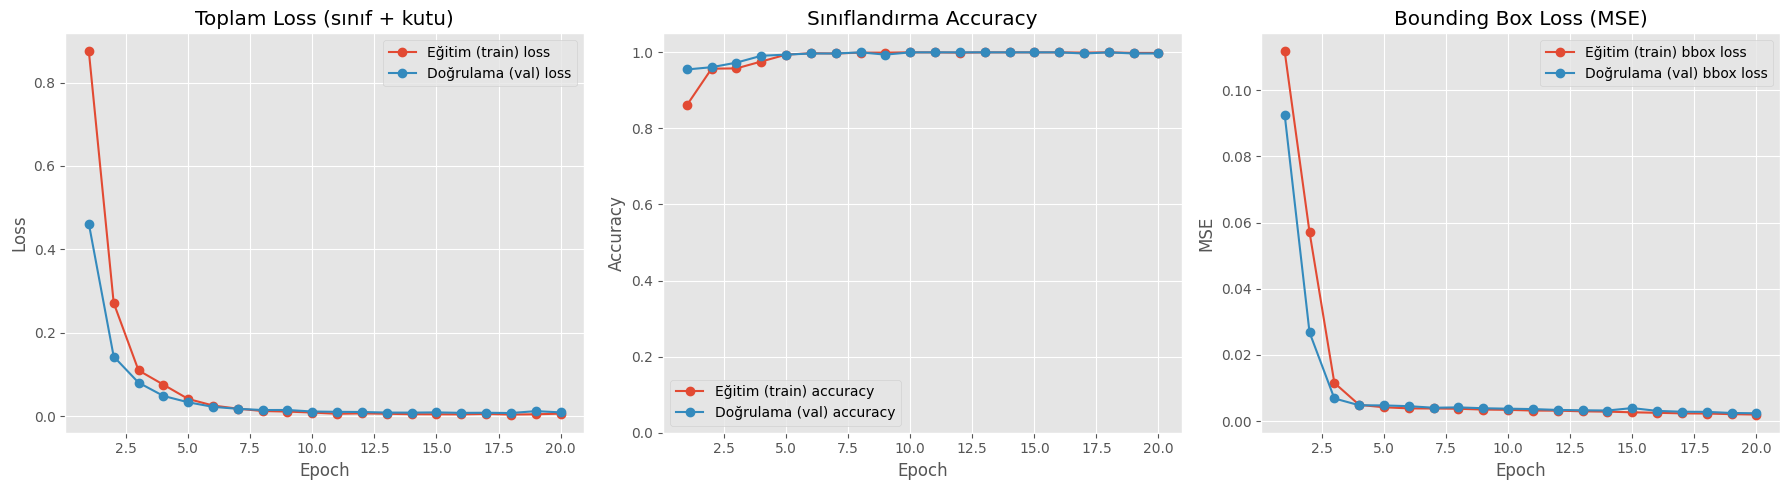

Son epoch -> Train acc: 0.9985 | Val acc: 0.9970 | Train loss: 0.0061 | Val loss: 0.0092


In [25]:
import json
import matplotlib.pyplot as plt
from pyimagesearch import config

# train.py'nin kaydettiği epoch geçmişini okuyoruz
with open(config.HISTORY_PATH) as f:
    H = json.load(f)

epochlar = range(1, len(H["total_train_loss"]) + 1)
plt.style.use("ggplot")
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# --- Toplam Loss: eğitim ve doğrulama ---
ax1.plot(epochlar, H["total_train_loss"], marker="o", label="Eğitim (train) loss")
ax1.plot(epochlar, H["total_val_loss"],   marker="o", label="Doğrulama (val) loss")
ax1.set_title("Toplam Loss (sınıf + kutu)")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()

# --- Sınıflandırma Accuracy: eğitim ve doğrulama ---
ax2.plot(epochlar, H["train_class_acc"], marker="o", label="Eğitim (train) accuracy")
ax2.plot(epochlar, H["val_class_acc"],   marker="o", label="Doğrulama (val) accuracy")
ax2.set_title("Sınıflandırma Accuracy")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1.05); ax2.legend()

# --- Bounding box Loss : kutuların ne kadar isabetli olduğunu gösterir ---
ax3.plot(epochlar, H["train_bbox_loss"], marker="o", label="Eğitim (train) bbox loss")
ax3.plot(epochlar, H["val_bbox_loss"],   marker="o", label="Doğrulama (val) bbox loss")
ax3.set_title("Bounding Box Loss (MSE)")
ax3.set_xlabel("Epoch"); ax3.set_ylabel("MSE"); ax3.legend()

plt.tight_layout()
plt.show()

# Son epoch değerlerini özet olarak yazdırıyoruz
print(f"Son epoch -> Train acc: {H['train_class_acc'][-1]:.4f} | Val acc: {H['val_class_acc'][-1]:.4f} | "
      f"Train loss: {H['total_train_loss'][-1]:.4f} | Val loss: {H['total_val_loss'][-1]:.4f}")

## 7. Inference (çıkarım) fonksiyonu — grafik arayüz olmadan (Ödev Madde 5)

Derin ogrenme modellerinde egitim sureci tamamlandiktan sonra, modelin daha once hic gormedigi yeni bir gorusel uzerinde tahmin yapmasi islemine Inference (Çıkarım) adi verilir. PyImageSearch uzerindeki orijinal predict.py betigi, tahmin sonuclarini cv2.imshow() ve cv2.waitKey() komutlarini kullanarak yerel bir masaustu penceresinde gostermek uzere kurgulanmistir.

Ancak Google Colab veya sunucu (headless) ortamlarinda fiziksel bir ekran / grafik arayuzu (GUI) bulunmaz. Bu ortamlarda cv2.imshow() cagrildiginda sistem cv2.error: System function call failed veya DisabledFunctionError hatasi vererek calismayi durdurur.

Bu sorunu asmak ve odevin Madde 5 gereksinimini tam olarak karsilamak amaciyla, yeni predict.py yapisinda tum grafik arayuz bagimliliklari kaldirilmis ve arayuzsuz calisan tahmin_et(goruntu_yolu) fonksiyonu gelistirilmistir.
Hiç pencere açmaz, sadece değer döndürür.

In [26]:
%%writefile predict.py
# ============================================================================
# predict.py : Eğitilmiş modelle tek bir görüntü için tahmin yapar.
# Grafik arayüz (pencere) KULLANMAZ; sonucu değer olarak döndürür.
#
# İki şekilde kullanılabilir:
#   1) Python'dan:   from predict import tahmin_et
#                    etiket, olasilik = tahmin_et("gorsel.jpg")
#   2) Terminalden:  !python predict.py --input gorsel.jpg
# ============================================================================
import argparse
import pickle

import cv2
import torch
import torch.nn.functional as F
from torchvision import transforms

from pyimagesearch import config
# torch.load ile bütün modeli açarken Python'un ObjectDetector sınıfını tanıması gerekir;
# bu import sınıfı belleğe yükler.
from pyimagesearch.bbox_regressor import ObjectDetector

# Model ve etiket kodlayıcıyı ilk tahminde bir kez yükleyip burada saklıyoruz
# (her çağrıda diskten tekrar okumamak için)
_model = None
_le = None

# Eğitimdeki ön işlemenin AYNISI olmak zorunda, yoksa tahminler bozulur
_donusum = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=config.MEAN, std=config.STD),
])


def model_yukle():
    # Kaydedilmiş modeli ve LabelEncoder'ı diskten yükler
    global _model, _le
    if _model is None:
        # [SÜRÜM DÜZELTMESİ] PyTorch 2.6+ sürümünde torch.load varsayılanı weights_only=True oldu.
        # torch.save(model) ile kaydedilen BÜTÜN model nesnesini yüklerken bu varsayılan "UnpicklingError: Weights only load failed" hatası verir. Bu yüzden weights_only=False.
        # (weights_only=False sadece kendi ürettiğimiz, güvendiğimiz dosyalarda kullanılmalı.)
        _model = torch.load(config.MODEL_PATH, map_location=config.DEVICE, weights_only=False)
        _model.eval()  # Değerlendirme modu: Dropout kapalı
        with open(config.LE_PATH, "rb") as f:
            _le = pickle.load(f)
    return _model, _le


def tahmin_et(goruntu_yolu, kutu_dondur=False):
    model, le = model_yukle()

    # 1) Görüntüyü oku
    image = cv2.imread(goruntu_yolu)
    if image is None:
        raise FileNotFoundError(f"Görüntü okunamadı: {goruntu_yolu}")
    (h, w) = image.shape[:2]  # Orijinal boyut (kutuyu geri ölçeklemek için)

    # 2) Eğitimdeki gibi ön işle
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (config.INPUT_SIZE, config.INPUT_SIZE))
    tensor = _donusum(image).unsqueeze(0).to(config.DEVICE)  # unsqueeze(0): batch boyutu ekler -> (1,3,224,224)

    # 3) Modeli çalıştır
    with torch.inference_mode():
        predBBox, predLogits = model(tensor)

    # 4) Ham skorları (logit) softmax ile olasılığa çevir; en yüksek olanı seç
    olasiliklar = F.softmax(predLogits, dim=1)[0]
    indeks = int(olasiliklar.argmax().item())
    olasilik = float(olasiliklar[indeks].item())
    etiket = str(le.inverse_transform([indeks])[0])  # Sayıyı tekrar sınıf ismine çevir

    if not kutu_dondur:
        return etiket, olasilik

    # 5)0-1 aralığındaki kutuyu orijinal görüntü pikseline geri ölçekle
    x1, y1, x2, y2 = predBBox[0].tolist()
    return etiket, olasilik, (int(x1 * w), int(y1 * h), int(x2 * w), int(y2 * h))


# Terminalden çalıştırma: orijinal projedeki gibi --input parametresi alır.
# [SÜRÜM DÜZELTMESİ] Orijinal predict.py argparse'ı dosyanın en üstünde çalıştırıyordu ve sonucu cv2.imshow ile gösteriyordu. Colab'da imshow "DisabledFunctionError" verdi; notebook içinden
# import edilince de argparse "SystemExit: 2" hatası verdi. Bu yüzden argparse'ı bu bloğa aldık,  sonucu ise pencere yerine yazdırıyoruz.
if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("-i", "--input", required=True, help="tahmin yapılacak görüntünün yolu")
    args = vars(ap.parse_args())
    etiket, olasilik = tahmin_et(args["input"])
    print(f"Tahmin: {etiket} | Olasılık: {olasilik:.4f}")

Writing predict.py


In [27]:
# ---------------- Örnek kullanım: tek bir test görüntüsü ----------------
from predict import tahmin_et
from pyimagesearch import config

# train.py'nin kaydettiği test görsellerinin listesini okuyoruz (eğitimde hiç görülmediler)
with open(config.TEST_PATHS) as f:
    test_listesi = [s.strip() for s in f if s.strip()]

ornek_yol = test_listesi[0]
etiket, olasilik = tahmin_et(ornek_yol)

print("Görüntü  :", ornek_yol)
print("Tahmin   :", etiket)
print(f"Olasılık : {olasilik:.4f}  (%{olasilik * 100:.2f})")

Görüntü  : /content/data/caltech101_classification/Motorbikes/image_0621.jpg
Tahmin   : Motorbikes
Olasılık : 1.0000  (%100.00)


In [28]:
# Aynı tahmini orijinal projedeki gibi terminalden de yapabiliriz
!python predict.py --input "{ornek_yol}"

Tahmin: Motorbikes | Olasılık: 1.0000


In [29]:
# ---------------- Rastgele 10 test görüntüsü üzerinde tahmin ----------------
import os
import random

random.seed(0)
secilenler = random.sample(test_listesi, min(10, len(test_listesi)))

print(f"{'Görüntü':45s} {'Gerçek':12s} {'Tahmin':12s} {'Olasılık':>9s}")
print("-" * 82)
for yol in secilenler:
    gercek = os.path.basename(os.path.dirname(yol))   # Gerçek sınıf = klasör adı
    tahmin, p = tahmin_et(yol)
    isaret = "✓" if tahmin == gercek else "✗"
    print(f"{os.path.relpath(yol, config.BASE_PATH)[-45:]:45s} {gercek:12s} {tahmin:12s} {p:9.4f} {isaret}")

Görüntü                                       Gerçek       Tahmin        Olasılık
----------------------------------------------------------------------------------
h101_classification/Motorbikes/image_0501.jpg Motorbikes   Motorbikes      0.9985 ✓
h101_classification/Motorbikes/image_0793.jpg Motorbikes   Motorbikes      1.0000 ✓
h101_classification/Motorbikes/image_0347.jpg Motorbikes   Motorbikes      1.0000 ✓
ch101_classification/airplanes/image_0762.jpg airplanes    airplanes       0.9999 ✓
h101_classification/Motorbikes/image_0173.jpg Motorbikes   Motorbikes      0.9998 ✓
ech101_classification/schooner/image_0019.jpg schooner     schooner        0.9949 ✓
h101_classification/Motorbikes/image_0296.jpg Motorbikes   Motorbikes      1.0000 ✓
ch101_classification/airplanes/image_0005.jpg airplanes    airplanes       0.9998 ✓
ch101_classification/airplanes/image_0708.jpg airplanes    airplanes       1.0000 ✓
ch101_classification/airplanes/image_0545.jpg airplanes    airplanes       0.99

In [33]:
# Test kümesinde yanlış tahmin edilen görüntüleri listeliyoruz
for yol in test_listesi:
    gercek = os.path.basename(os.path.dirname(yol))
    tahmin, p = tahmin_et(yol)
    if tahmin != gercek:
        print(f"{yol}\n  Gerçek: {gercek} | Tahmin: {tahmin} | Olasılık: {p:.4f}")

/content/data/caltech101_classification/Motorbikes/image_0237.jpg
  Gerçek: Motorbikes | Tahmin: airplanes | Olasılık: 0.6912


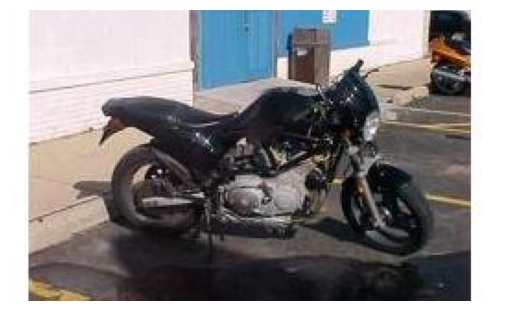

In [36]:
   import matplotlib.pyplot as plt, cv2
   img = cv2.cvtColor(cv2.imread("/content/data/caltech101_classification/Motorbikes/image_0237.jpg"), cv2.COLOR_BGR2RGB)
   plt.imshow(img); plt.axis("off"); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [30]:
# ---------------- Tüm test kümesinde doğruluk (accuracy) ----------------
dogru = sum(int(tahmin_et(yol)[0] == os.path.basename(os.path.dirname(yol))) for yol in test_listesi)
print(f"Test accuracy (tahmin_et ile): {dogru}/{len(test_listesi)} = {dogru / len(test_listesi):.4f}")

Test accuracy (tahmin_et ile): 332/333 = 0.9970


In [31]:
# ----------------Tahmin edilen kutuyu dosyaya çizme ----------------
# Pencere AÇMADAN sonucu bir görüntü dosyasına kaydediyoruz.
import cv2

etiket, olasilik, (x1, y1, x2, y2) = tahmin_et(ornek_yol, kutu_dondur=True)

img = cv2.imread(ornek_yol)
cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)                         # Tahmin edilen kutu
cv2.putText(img, f"{etiket} {olasilik:.2f}", (x1, max(15, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)                     # Etiket yazısı

cikti_gorsel = os.path.join(config.BASE_OUTPUT, "ornek_tahmin.jpg")
cv2.imwrite(cikti_gorsel, img)
print("Kaydedildi:", cikti_gorsel, "| Kutu:", (x1, y1, x2, y2))

Kaydedildi: /content/output/ornek_tahmin.jpg | Kutu: (32, 22, 229, 152)


## 8. Sürüm kaynaklı hatalar ve çözümleri (Ödev Madde 3)

| # | Orijinal kod | Güncel ortamda sorun | Çözüm | Nerede |
|---|---|---|---|---|
| 1 | `resnet50(pretrained=True)` | torchvision ≥ 0.13'te `pretrained` kullanımdan kaldırıldı; uyarı / güncel sürümlerde hata | `resnet50(weights=ResNet50_Weights.DEFAULT)` | `train.py` |
| 2 | `torch.load(config.MODEL_PATH)` | PyTorch ≥ 2.6'da `weights_only=True` varsayılan oldu; bütün modeli yüklerken `UnpicklingError` | `torch.load(..., weights_only=False)` + ayrıca `state_dict` kaydı | `predict.py` |
| 3 | `cv2.imshow("Output", image)` | Colab'da ekran yok; `DisabledFunctionError` | Sonuç değer olarak döndürülür (`tahmin_et`) | `predict.py` |
| 4 | Dosya başında `argparse` | Notebook'tan import edilince `SystemExit: 2` | `argparse` sadece `if __name__ == "__main__":` içinde | `predict.py` |
| 5 | `num_workers=os.cpu_count()` | Colab'da "worker sayısı fazla" uyarısı ve takılma riski | `NUM_WORKERS = 2` | `config.py` |
| 6 | `dataset/annotations/*.csv` + `dataset/images/` | Kaggle setinin klasör/annotation yapısı farklı | CSV ve `.mat` formatlarını otomatik tanıyan okuyucu | `veri_okuyucu.py` |
| 7 | `imutils.paths` | Paket Colab'da kurulu gelmeyebilir (`ModuleNotFoundError`) | Standart `glob` kullanıldı | `veri_okuyucu.py` |  
 | 8 | Annotation arşivini `urllib.request.urlretrieve` ile indirme | Caltech sunucusu Python'un varsayılan isteğini `HTTP Error 403: Forbidden` ile reddetti | İsteğe tarayıcı `User-Agent` başlığı eklendi; olmazsa torchvision indiricisine geçiliyor | Annotation indirme hücresi |

##9. Üretilen dosyaları indirme

In [35]:
import shutil
from google.colab import files

# Proje dosyalarını ve çıktıları geçici bir klasörde toplayıp zip'liyoruz
shutil.rmtree("/content/teslim", ignore_errors=True)
shutil.copytree("/content/pyimagesearch", "/content/teslim/pyimagesearch",
                ignore=shutil.ignore_patterns("__pycache__"))
shutil.copytree("/content/output", "/content/teslim/output")
shutil.copy("/content/train.py", "/content/teslim/")
shutil.copy("/content/predict.py", "/content/teslim/")

zip_yolu = shutil.make_archive("/content/object_detector_proje", "zip", "/content/teslim")
print("Zip oluşturuldu:", zip_yolu)
files.download(zip_yolu)

Zip oluşturuldu: /content/object_detector_proje.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>